# Braude College of Engineering - Data Mining & Machine Learning (61761)
# Lab 3: Distance Measures & Hierarchical Clustering

### 1. Imports

In [43]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage
from scipy.spatial.distance import pdist, squareform
from sklearn.datasets import load_wine

### 2. Dataset Loading & Feature Selection

In [44]:
# Load a subset of the Wine dataset for clean distance and cluster demonstration
wine = load_wine(as_frame=True)
df = wine.frame

# Use a small subset of 30 samples and 3 features for clear demonstration
features = ["alcohol", "malic_acid", "flavanoids"]
df_sub = df[features].iloc[:30].copy()

print(f"Subset shape: {df_sub.shape}")
display(df_sub.head())

Subset shape: (30, 3)


,alcohol,malic_acid,flavanoids
0,14.23,1.71,3.06
1,13.20,1.78,2.76
2,13.16,2.36,3.24
3,14.37,1.95,3.49
4,13.24,2.59,2.69


### 3. Distance Computation (Euclidean Demo)

In [45]:
# Compute pairwise Euclidean distances
dist_euclidean_condensed = pdist(df_sub, metric="euclidean")
dist_euclidean_matrix = squareform(dist_euclidean_condensed)

print("Distance Matrix Shape:", dist_euclidean_matrix.shape)
print("Distance between sample 0 and sample 1:", round(dist_euclidean_matrix[0, 1], 4))
print("Max Euclidean Distance:", round(dist_euclidean_matrix.max(), 4))

Distance Matrix Shape: (30, 30)
Distance between sample 0 and sample 1: 1.0751
Max Euclidean Distance: 3.039


### 4. Hierarchical Clustering (Single Linkage Demo)

In [46]:
# Perform Hierarchical Linkage using the 'single' method
Z_single = linkage(dist_euclidean_condensed, method="single")

# The linkage matrix has shape (n-1, 4)
# Columns: [cluster1, cluster2, distance, sample_count]
print("Final merge distance (Single Link):", round(Z_single[-1, 2], 4))

Final merge distance (Single Link): 1.1741


### 5. Dendrogram Plotting & Cluster Extraction Demo

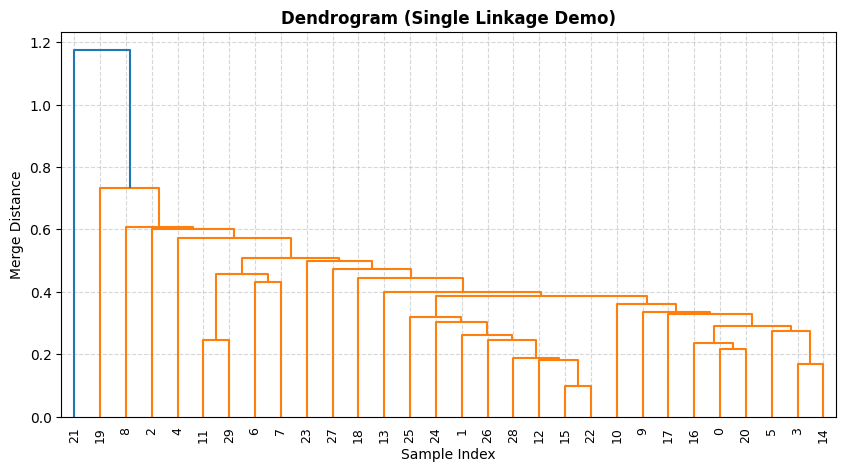

Cluster Counts (Single Link, K=3):
1    28
2     1
3     1
Name: count, dtype: int64


In [47]:
# Plot Dendrogram
plt.figure(figsize=(10, 5))
dendrogram(Z_single, leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrogram (Single Linkage Demo)", fontsize=12, fontweight="bold")
plt.xlabel("Sample Index")
plt.ylabel("Merge Distance")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# Extract clusters for K=3 using fcluster
clusters_demo = fcluster(Z_single, t=3, criterion="maxclust")
print("Cluster Counts (Single Link, K=3):")
print(pd.Series(clusters_demo).value_counts().sort_index())

## PART B: Independent Student Tasks

### Task 1: Distance Metric Comparison (Euclidean vs. Manhattan)
1. Compute the pairwise distance matrix on `df_sub` using the `cityblock` (Manhattan) metric.
2. Print the maximum distance found in the Euclidean matrix and the Manhattan matrix.

In [48]:
# TODO 1.1: Compute Manhattan pairwise distance
dist_manhattan_condensed = pdist(df_sub, metric="cityblock")
dist_manhattan_matrix = squareform(dist_manhattan_condensed)

# TODO 1.2: Print max distance for both Euclidean and Manhattan matrices
print("Max Euclidean Distance:", round(dist_euclidean_matrix.max(), 4))
print("Max Manhattan Distance:", round(dist_manhattan_matrix.max(), 4))

Max Euclidean Distance: 3.039
Max Manhattan Distance: 5.17


### Task 2: Linkage Criteria Comparison (Single vs. Complete vs. Average)
1. Compute the linkage matrix using the `complete` method on the Euclidean distance.
2. Compute the linkage matrix using the `average` method on the Euclidean distance.
3. Print the final merge distance (last row, column index 2) for all 3 methods: Single, Complete, and Average.

In [49]:
# TODO 2.1: Compute Z_complete and Z_average
Z_complete = linkage(dist_euclidean_condensed, method="complete")
Z_average = linkage(dist_euclidean_condensed, method="average")

# TODO 2.2: Print final merge distance for Single, Complete, and Average
print("Final merge distance (Single Link):", round(Z_single[-1, 2], 4))
print("Final merge distance (Complete Link):", round(Z_complete[-1, 2], 4))
print("Final merge distance (Average Link):", round(Z_average[-1, 2], 4))


Final merge distance (Single Link): 1.1741
Final merge distance (Complete Link): 3.039
Final merge distance (Average Link): 2.2967


### Task 3: Dendrogram Plotting & Cluster Extraction
1. Plot the Dendrogram for the `complete` linkage model.
2. Extract cluster labels for $K=3$ clusters using `fcluster(..., t=3, criterion='maxclust')`.
3. Print the cluster size distribution using `value_counts()`.

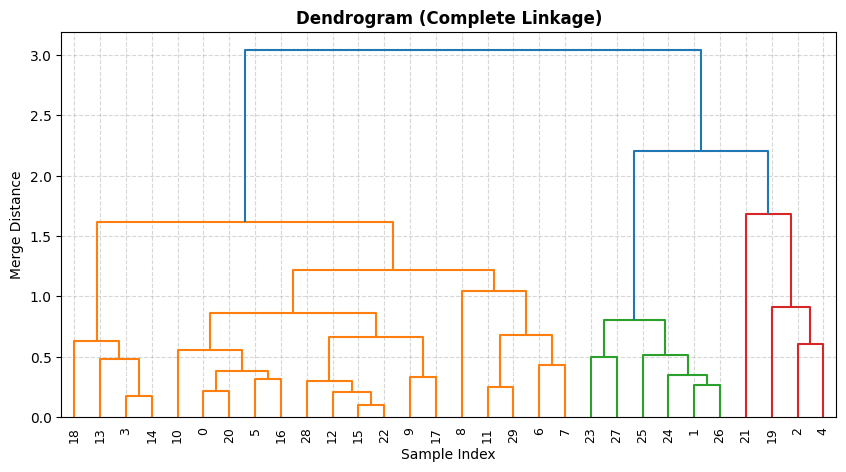

Cluster Counts (Complete Linkage, K=3):
1    20
2     6
3     4
Name: count, dtype: int64


In [50]:
# TODO 3.1: Plot Dendrogram for Complete Linkage
plt.figure(figsize=(10, 5))
dendrogram(Z_complete, leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrogram (Complete Linkage)", fontsize=12, fontweight="bold")
plt.xlabel("Sample Index")
plt.ylabel("Merge Distance")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

# TODO 3.2: Extract K=3 clusters and print their size distribution
clusters_complete = fcluster(Z_complete, t=3, criterion="maxclust")
print("Cluster Counts (Complete Linkage, K=3):")
print(pd.Series(clusters_complete).value_counts().sort_index())

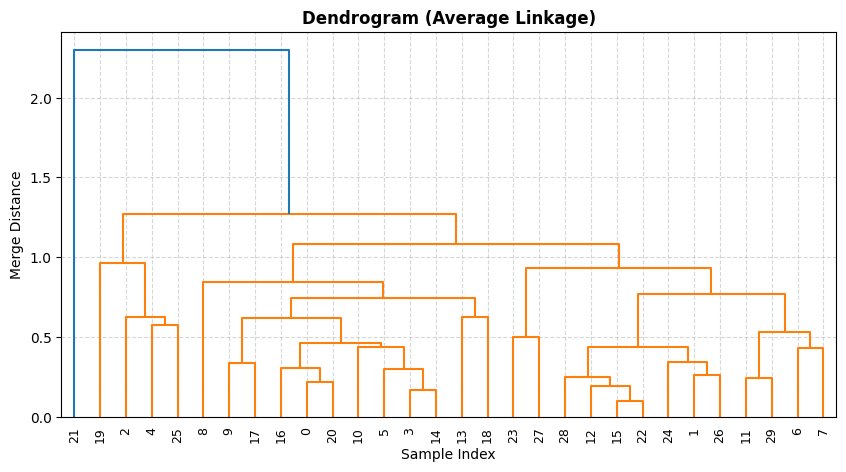

In [51]:
# TODO 4.1: Plot Dendrogram for Average Linkage
# **********************FOR MYSELF*********************
plt.figure(figsize=(10, 5))
dendrogram(Z_average, leaf_rotation=90, leaf_font_size=9)
plt.title("Dendrogram (Average Linkage)", fontsize=12, fontweight="bold")
plt.xlabel("Sample Index")
plt.ylabel("Merge Distance")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

### Task 4: Conceptual Understanding
**Question:** Why is the final merge distance in Complete-linkage always greater than or equal to the final merge distance in Single-linkage on the same dataset?  
*(Write your 1-2 sentence answer below)*

**Answer for Task 4:**
In the final merge, Single-linkage measures the distance between the closest pair of points across the two remaining clusters, while Complete-linkage measures the distance between the farthest pair. Since a minimum over a set of distances is always ≤ its maximum, the Complete-linkage final merge distance is always ≥ the Single-linkage one. In fact, the Complete-linkage final merge equals the largest pairwise distance in the whole dataset, which is an upper bound for any single-link merge distance.


אותן שתי קבוצות, ושתי תשובות שונות. התשובה הראשונה היא תמיד קטנה או שווה לשנייה, כי הקרוב ביותר לא יכול להיות רחוק יותר מהרחוק ביותר. אפילו כשיש רק זוג אחד אפשרי הם יוצאים שווים.

ועכשיו למיזוג האחרון: שם נשארו שתי קבוצות בלבד, שביחד מכילות את כל הדגימות, והאלגוריתם מאחד אותן. המרחק ש-Z[-1, 2] מציג הוא בדיוק "כמה רחוקות שתי הקבוצות האלה", ומחושב לפי השיטה:

ב-Single: מרחק בין הזוג הקרוב ביותר בין הקבוצות.
ב-Complete: מרחק בין הזוג הרחוק ביותר בין הקבוצות.